In [1]:
w1 = 1E-3	# 1E-4
w2 = 1E-5	# 1E-4

In [2]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import bom_sep as bom
from models import hgm_sep as hgm

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

# Functions

In [4]:
def fit_model(splits, B_ll, N_res):
	p = 2

	model_per_split = list()
	neuron_score_per_split = list()
	mpe_loss_per_split = list()
	mpe_loss_tr_per_split = list()
	for train, eval in splits:
		B_ll_train, B_ll_eval = B_ll[train], B_ll[eval]
		N_res_train, N_res_eval = N_res[train], N_res[eval]

		model = LinearRegression(fit_intercept=False)
		model.fit(B_ll_train, N_res_train)

		N_res_pred = model.predict(B_ll_eval)

		loss = jnp.mean(jnp.mean(jnp.abs(N_res_pred - N_res_eval) ** p, axis=0))
		loss_tr = jnp.mean(jnp.mean(jnp.abs(model.predict(B_ll_train) - N_res_train) ** p, axis=0))

		score_per_neuron = [(r2_score(trace, trace_pred) if trace.var() > 0 else 0) for trace, trace_pred in zip(N_res_eval.T, N_res_pred.T)]

		model_per_split.append(model)
		neuron_score_per_split.append(np.array(score_per_neuron))
		mpe_loss_per_split.append(loss)
		mpe_loss_tr_per_split.append(loss_tr)

	return model_per_split, np.array(neuron_score_per_split), np.array(mpe_loss_per_split), np.array(mpe_loss_tr_per_split)

In [5]:
def fit_models(filenames, discrete_states, eigenworms, traces_residual):
	models_models_art = list()
	models_scores_art = list()
	models_mpe_losses_art = list()
	models_mpe_losses_tr_art = list()

	for i in range(len(filenames)):
		print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(model_per_split,
		 neuron_score_per_split,
		 mpe_loss_per_split, mpe_loss_tr_per_split) = fit_model(splits,
												   eigenworms[i].values,
												   traces_residual[i].values)

		models_models_art.append(model_per_split)
		models_scores_art.append(neuron_score_per_split)
		models_mpe_losses_art.append(mpe_loss_per_split)
		models_mpe_losses_tr_art.append(mpe_loss_tr_per_split)

	return models_models_art, models_scores_art, models_mpe_losses_art, models_mpe_losses_tr_art

In [6]:
def train_model(model, splits, B_ll, N_res, N_man=None, hyperparameters=None):
	is_hgm = model.get_type()

	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 2000,
			'max_patience': 2000 / 4,
			'learning_rate': 1E-1,
			'w1_reg_lambda': w1, #0.0,
			'w2_reg_lambda': w2, #0.0,
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	reg_lambdas = hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']
	#endregion ===========================================================================

	n_neurons = N_res.shape[1]
	if is_hgm: n_dimensions = N_man.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =============================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mpe_losses_per_split = list()
	mpe_losses_tr_per_split = list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])
		if is_hgm: N_man_train, N_man_eval = jnp.array(N_man[train]), jnp.array(N_man[eval])
		N_res_train, N_res_eval = jnp.array(N_res[train]), jnp.array(N_res[eval])

		if is_hgm:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons))

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(
		# 	init_value=learning_rate,
		# 	decay_steps=max_epochs,
		# 	alpha=1E-2
		# ))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, B_ll_eval, N_man_eval, N_res_eval, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_eval, N_man_eval, N_res_eval).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()]
		else:
			losses = [model.loss_fn(params, B_ll_eval, N_res_eval, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_eval, N_res_eval).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_res_train).item()]

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mpe_loss = sys.float_info.max
		best_mpe_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state = model.update(optimizer.update, opt_state, params, B_ll_train, N_man_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_eval, N_man_eval, N_res_eval, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_eval, N_man_eval, N_res_eval).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()
			else:
				params, opt_state  = model.update(optimizer.update, opt_state, params, B_ll_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_eval, N_res_eval, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_eval, N_res_eval).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_res_train).item()

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mpe_loss = mpe_loss
					best_mpe_loss_tr = mpe_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]
						mpe_losses_tr = mpe_losses_tr + [best_mpe_loss_tr for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses.append(loss)
			losses_tr.append(loss_tr)
			mpe_losses.append(mpe_loss)
			mpe_losses_tr.append(mpe_loss_tr)

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mpe_losses_per_split.append(mpe_losses)
		mpe_losses_tr_per_split.append(mpe_losses_tr)

		print(f'Split {s_id} completed. ', end='')

		# predicting and scoring ========================================================================
		if is_hgm:
			score_per_neuron = model.score_fn(params, B_ll_eval, N_man_eval, N_res_eval)
		else:
			score_per_neuron = model.score_fn(params, B_ll_eval, N_res_eval)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# ===========================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mpe_losses_per_split), np.array(mpe_losses_tr_per_split)

In [7]:
def train_models(model, filenames, discrete_states, eigenworms, traces_residual, neural_modes=None):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mpe_losses = list()
	models_mpe_losses_tr = list()

	for i in range(len(filenames)):
		print(f'\n{i + 1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mpe_losses_per_split, mpe_losses_tr_per_split) = train_model(
			model, splits,
			eigenworms[i].values,
			traces_residual[i].values,
			neural_modes[i].values if neural_modes is not None else None)

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mpe_losses.append(mpe_losses_per_split)
		models_mpe_losses_tr.append(mpe_losses_tr_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mpe_losses, models_mpe_losses_tr

In [8]:
def assemble(filenames, traces, bom_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	bom_models_avg_scores = [np.mean(scores, axis=0) for scores in bom_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, bom_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [9]:
read_ids = [0, 12, 14, 23, 29, 32]
# read_ids = [14]
plot_id = 14

# selection_n = ['VB02', 'SMDDR', 'RMDDR', 'AVAR']
selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 2
dims_generation = 2
weights = (0.5, 2.)


regression = False
artificial = False
gfp = False

# read & preprocess (GCamp & GFP)

In [10]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids_gcamp, filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, read_ids)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	file_ids_gfp, filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

	for i in range(len(filenames_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		traces_gfp[i] = traces_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

# ARTIFICIAL DATA

In [11]:
if artificial:
	file_ids_art = file_ids_gcamp.copy()
	filenames_art = list()
	discrete_states_art = discrete_states_gcamp.copy()
	eigenworms_art = eigenworms_gcamp.copy()
	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()
	for i in range(len(filenames_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

In [12]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[file_ids_art.index(plot_id)]}] artificial neural traces residual',
						   discrete_states_art[file_ids_art.index(plot_id)]['REV'],
						   traces_residual_art[file_ids_art.index(plot_id)][selection_n],
						   plots_per_row=1, ylimits=None)

In [13]:
if artificial and regression:
	# train blr art

	(blr_models_models_art,
	 blr_models_scores_art,
	 blr_models_losses_art, blr_models_losses_tr_art) = fit_models(filenames_art,
																			  discrete_states_art,
																			  eigenworms_art,
																			  traces_residual_art)

In [14]:
if artificial:
	# train bom art

	(bom_models_params_art,
	 bom_models_scores_art,
	 bom_models_losses_art, bom_models_losses_tr_art,
	 bom_models_mpe_losses_art, bom_models_mpe_losses_tr_art) = train_models(
		bom,
		filenames_art,
		discrete_states_art,
		eigenworms_art,
		traces_residual_art)

In [15]:
if artificial and regression:
	plot_utils.plot_losses_splits('artificial bom vs blr: mpe train',
								  filenames_art,
								  bom_models_mpe_losses_tr_art, [loss[:, None] * np.ones((1, bom_models_mpe_losses_tr_art[0].shape[1])) for loss in blr_models_losses_tr_art],
								  plots_per_row=4, ylimits=None)

In [16]:
if artificial and regression:
	plot_utils.plot_losses_splits('artificial bom vs blr: mpe eval',
								  filenames_art,
								  bom_models_mpe_losses_art, [loss[:, None] * np.ones((1, bom_models_mpe_losses_art[0].shape[1])) for loss in blr_models_losses_art],
								  plots_per_row=4, ylimits=None)

In [17]:
if artificial:
	# train hgm art

	(hgm_models_params_art,
	 hgm_models_scores_art,
	 hgm_models_losses_art, hgm_models_losses_tr_art,
	 hgm_models_mpe_losses_art, hgm_models_mpe_losses_tr_art) = train_models(
		hgm,
		filenames_art,
		discrete_states_art,
		eigenworms_art,
		traces_residual_art,
		neural_modes_art)

In [18]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe train',
								  filenames_art,
								  hgm_models_mpe_losses_tr_art, bom_models_mpe_losses_tr_art,
								  plots_per_row=4, ylimits=None)

In [19]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe eval',
								  filenames_art,
								  hgm_models_mpe_losses_art, bom_models_mpe_losses_art,
								  plots_per_row=4, ylimits=None)

### performance

In [20]:
if artificial:
	# assemble_art

	neuron_scores_art = assemble(filenames_art, traces_art, bom_models_scores_art, hgm_models_scores_art)

In [21]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in selection_n}, None,
									 limits=None, content_size=20)

In [22]:
if artificial:
	plot_utils.plot_improvement_plot({key: neuron_scores_art[key] for key in selection_n}, None,
									 limits=None, content_size=20)

### traces check

In [23]:
if artificial:
	blr_predicted_traces_art = [[
		pd.DataFrame(data=model.predict(eigenworms_art[i].values),
					 columns=traces_art[i].columns) for model in blr_models_models_art[i]
	] for i in range(len(traces_art))]

	bom_predicted_traces_art = [[
		pd.DataFrame(data=bom.predict(eigenworms_art[i].values, params['W']),
					 columns=traces_art[i].columns) for params in bom_models_params_art[i]
	] for i in range(len(traces_art))]

	hgm_predicted_traces_art = [[
		pd.DataFrame(data=hgm.predict(eigenworms_art[i].values, neural_modes_art[i].values, params['W1'], params['W2']),
					 columns=traces_art[i].columns) for params in hgm_models_params_art[i]
	] for i in range(len(traces_art))]

In [24]:
if artificial:
	# # best improvements
	# neuron_diffs = {key: np.mean(neuron_scores_art[key][1] - neuron_scores_art[key][0]) for key in neuron_scores_art.keys()}
	# selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_art[plot_id].columns][:4]
	#
	# # best hgm scores
	# neuron_hgmss = {key: np.mean(neuron_scores_art[key][1]) for key in neuron_scores_art.keys()}
	# selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_art[plot_id].columns][:4]

	pass

In [25]:
if artificial:
	splits = 1
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} splits {1}-{splits} artificial hgm & bom predictions residuals',
		discrete_states_art[file_ids_art.index(plot_id)]['REV'],
		traces_residual_art[file_ids_art.index(plot_id)][selection_n],
		[hgm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		[bom_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.8, 0.8))

In [26]:
if artificial:
	splits = 1
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} splits {1}-{splits} artificial hgm & bom predictions residuals',
		discrete_states_art[file_ids_art.index(plot_id)]['REV'],
		traces_residual_art[file_ids_art.index(plot_id)][selection_n],
		[hgm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		[bom_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.8, 0.8), plot_first=True)

# GCAMP

### manifold

In [27]:
(neural_modes_gcamp, _,
 traces_manifold_gcamp, _,
 cca_loadings_man_gcamp, _,
 vars_expl_man_gcamp, vars_expl_man_rs_gcamp) = train_utils.get_manifolds(traces_gcamp,
																		  discrete_states_gcamp,
																		  n_cc=dims, n_pc=5)

traces_residual_gcamp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gcamp, traces_manifold_gcamp)]

0.4384350146271195 0.6924493681885114


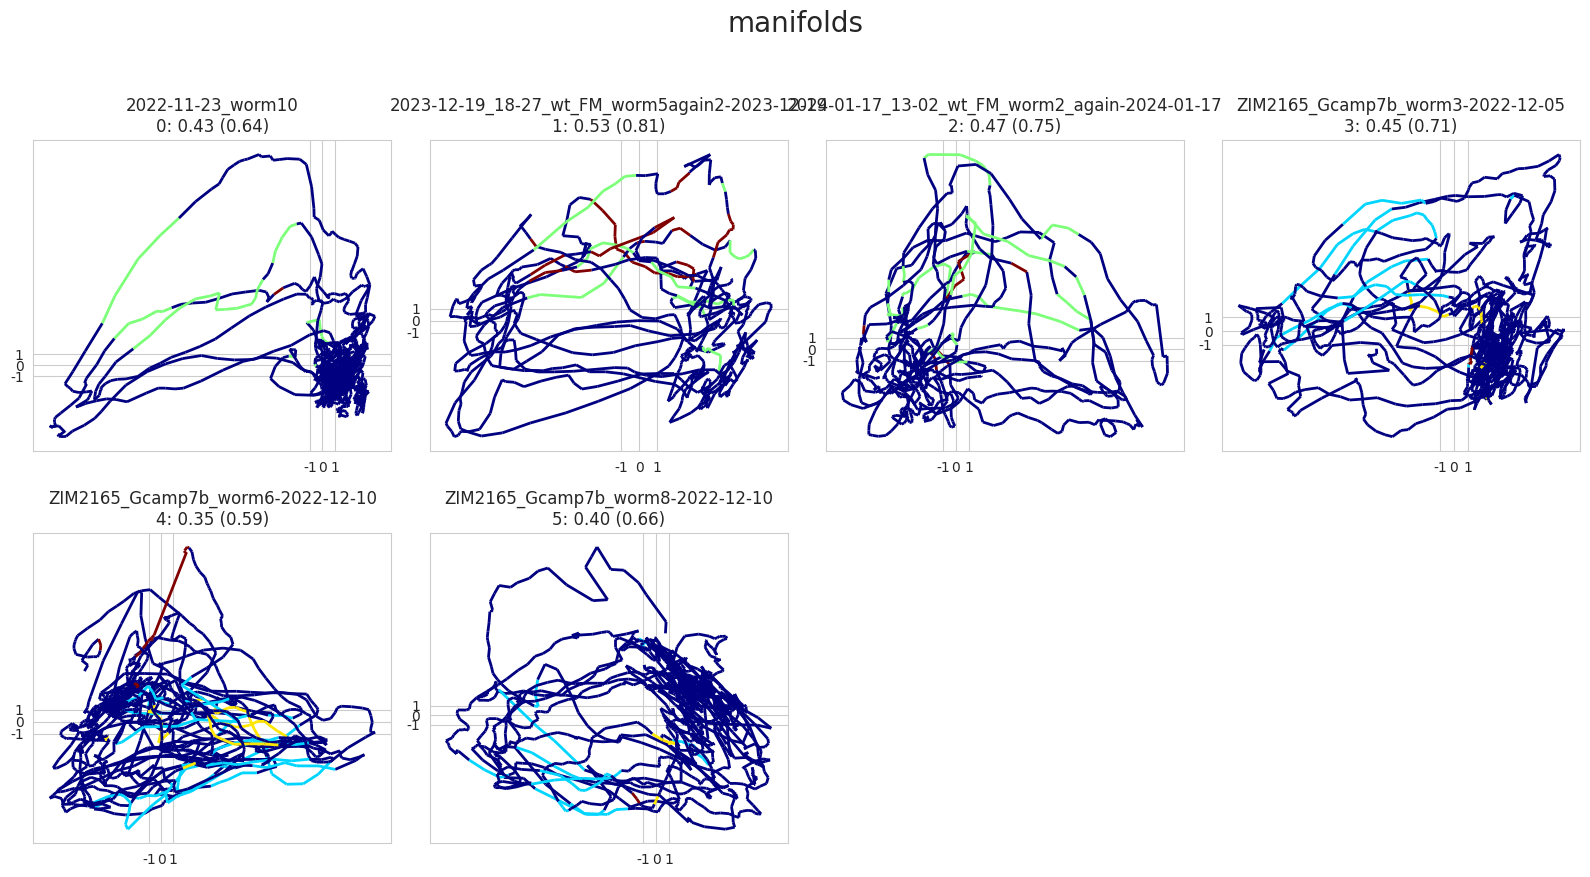

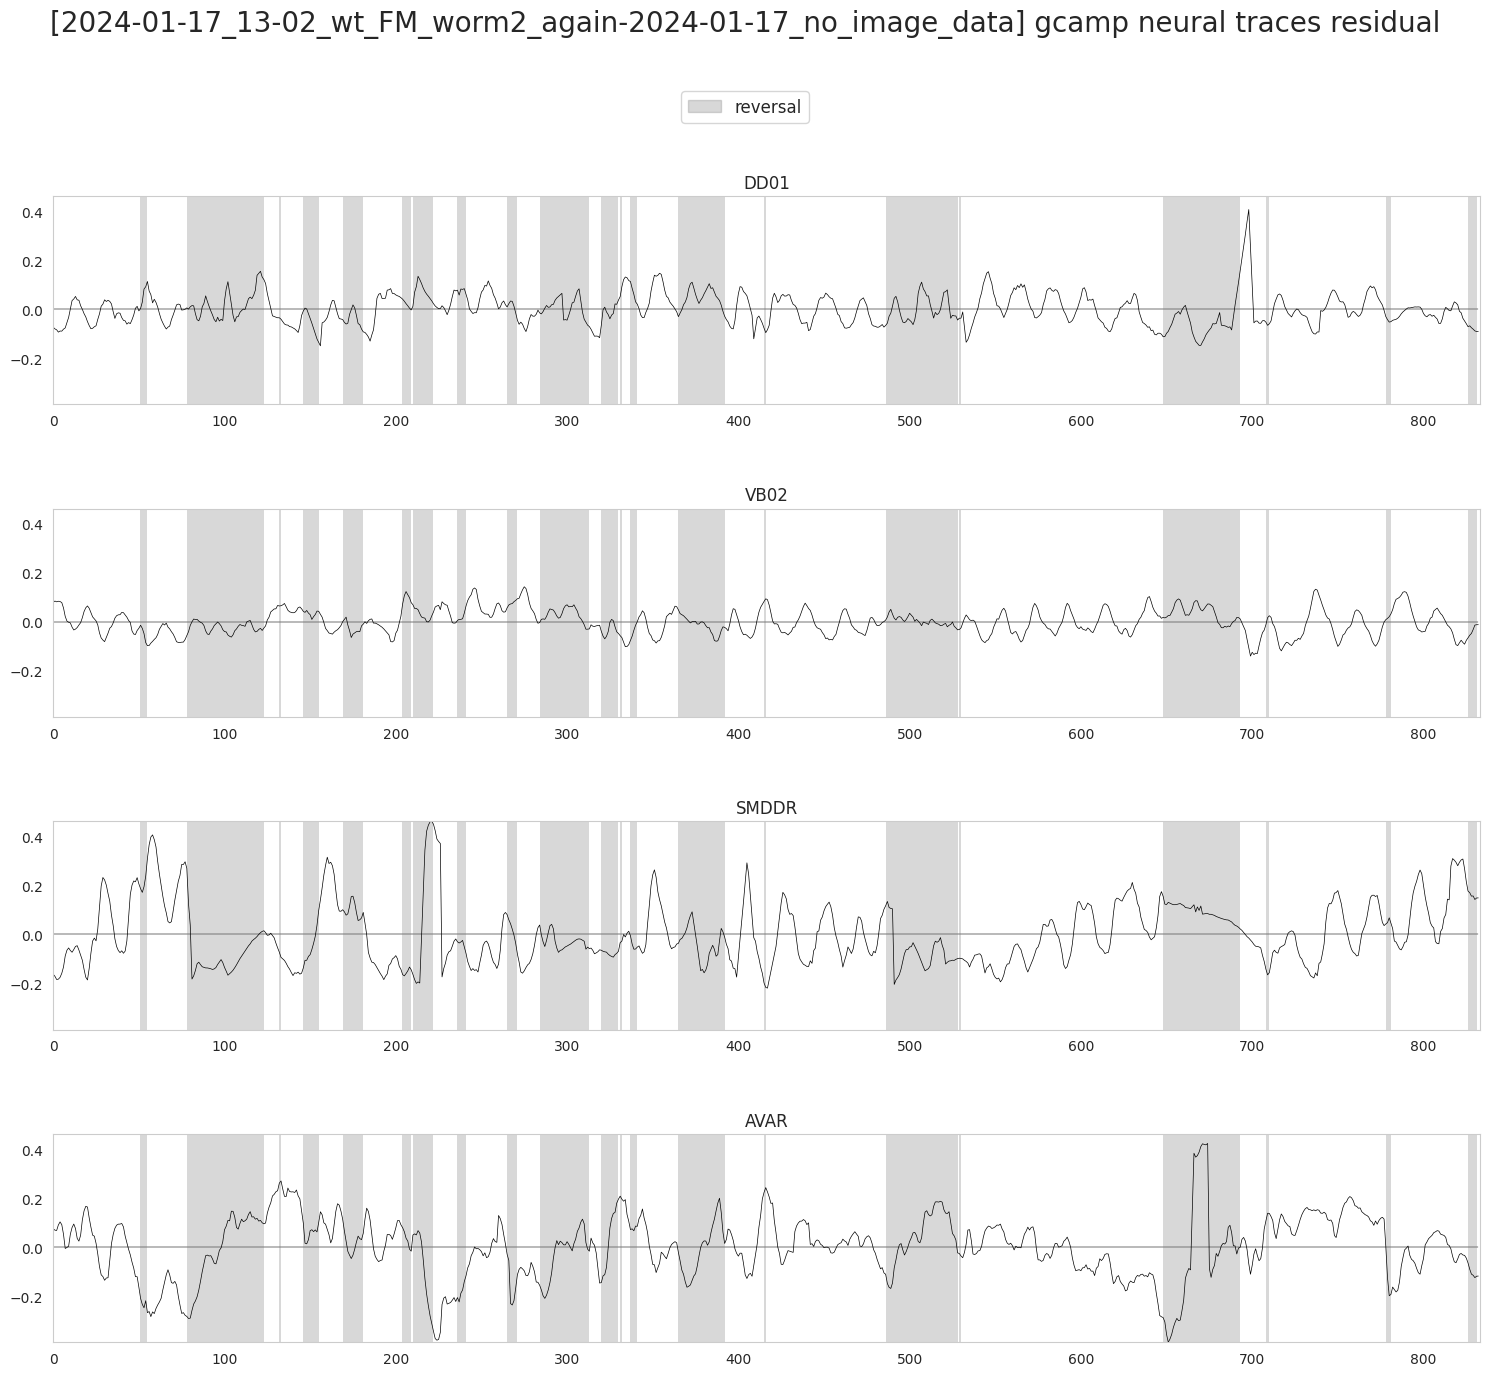

In [28]:
plot_utils.plot_manifolds(filenames_gcamp,
						  neural_modes_gcamp,
						  discrete_states_gcamp,
						  vars_expl_man_gcamp, vars_expl_man_rs_gcamp,
						  plots_per_row=4)

plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] gcamp neural traces residual',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
					   traces_residual_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

### BLR

In [29]:
if regression:
	(blr_models_models_gcamp,
	 blr_models_scores_gcamp,
	 blr_models_losses_gcamp, blr_models_losses_tr_gcamp) = fit_models(filenames_gcamp,
																				  discrete_states_gcamp,
																				  eigenworms_gcamp,
																				  traces_residual_gcamp)

### BOM

In [30]:
(bom_models_params_gcamp,
 bom_models_scores_gcamp,
 bom_models_losses_gcamp, bom_models_losses_tr_gcamp,
 bom_models_mpe_losses_gcamp, bom_models_mpe_losses_tr_gcamp) = train_models(
	bom,
	filenames_gcamp,
	discrete_states_gcamp,
	eigenworms_gcamp,
	traces_residual_gcamp)


1/6: 2022-11-23_worm10_no_image_data Stopped after 1040 epochs: Split 0 completed. Stopped after 1056 epochs: Split 1 completed. Stopped after 1269 epochs: Split 2 completed. Stopped after 1014 epochs: Split 3 completed. Stopped after 1454 epochs: Split 4 completed. 
2/6: 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19_no_image_data Stopped after 1851 epochs: Split 0 completed. Stopped after 1521 epochs: Split 1 completed. Stopped after 1264 epochs: Split 2 completed. Stopped after 1595 epochs: Split 3 completed. Stopped after 1546 epochs: Split 4 completed. 
3/6: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1092 epochs: Split 0 completed. Stopped after 1038 epochs: Split 1 completed. Stopped after 1165 epochs: Split 2 completed. Stopped after 1272 epochs: Split 3 completed. Stopped after 1165 epochs: Split 4 completed. 
4/6: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data Stopped after 1077 epochs: Split 0 completed. Stopped after 1080 epochs: Split 1 comple

In [31]:
if regression:
	plot_utils.plot_losses_splits('gcamp bom vs blr: mpe train',
								  filenames_gcamp,
								  bom_models_mpe_losses_tr_gcamp, [loss[:, None] * np.ones((1, bom_models_mpe_losses_tr_gcamp[0].shape[1])) for loss in blr_models_losses_tr_gcamp],
								  plots_per_row=4, ylimits=None)

In [32]:
if regression:
	plot_utils.plot_losses_splits('gcamp bom vs blr: mpe eval',
								  filenames_gcamp,
								  bom_models_mpe_losses_gcamp,  [loss[:, None] * np.ones((1, bom_models_mpe_losses_gcamp[0].shape[1])) for loss in blr_models_losses_gcamp],
								  plots_per_row=4, ylimits=None)

### HGM

In [33]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mpe_losses_gcamp, hgm_models_mpe_losses_tr_gcamp) = train_models(
	hgm,
	filenames_gcamp,
	discrete_states_gcamp,
	eigenworms_gcamp,
	traces_residual_gcamp,
	neural_modes_gcamp)


1/6: 2022-11-23_worm10_no_image_data Stopped after 1118 epochs: Split 0 completed. Stopped after 1876 epochs: Split 1 completed. Stopped after 1177 epochs: Split 2 completed. Stopped after 1267 epochs: Split 3 completed. Stopped after 1547 epochs: Split 4 completed. 
2/6: 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19_no_image_data Stopped after 1315 epochs: Split 0 completed. Stopped after 1030 epochs: Split 1 completed. Stopped after 1310 epochs: Split 2 completed. Stopped after 1279 epochs: Split 3 completed. Stopped after 1524 epochs: Split 4 completed. 
3/6: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1096 epochs: Split 0 completed. Stopped after 1135 epochs: Split 1 completed. Stopped after 1009 epochs: Split 2 completed. Stopped after 1102 epochs: Split 3 completed. Stopped after 1085 epochs: Split 4 completed. 
4/6: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data Stopped after 1085 epochs: Split 0 completed. Stopped after 1941 epochs: Split 1 comple

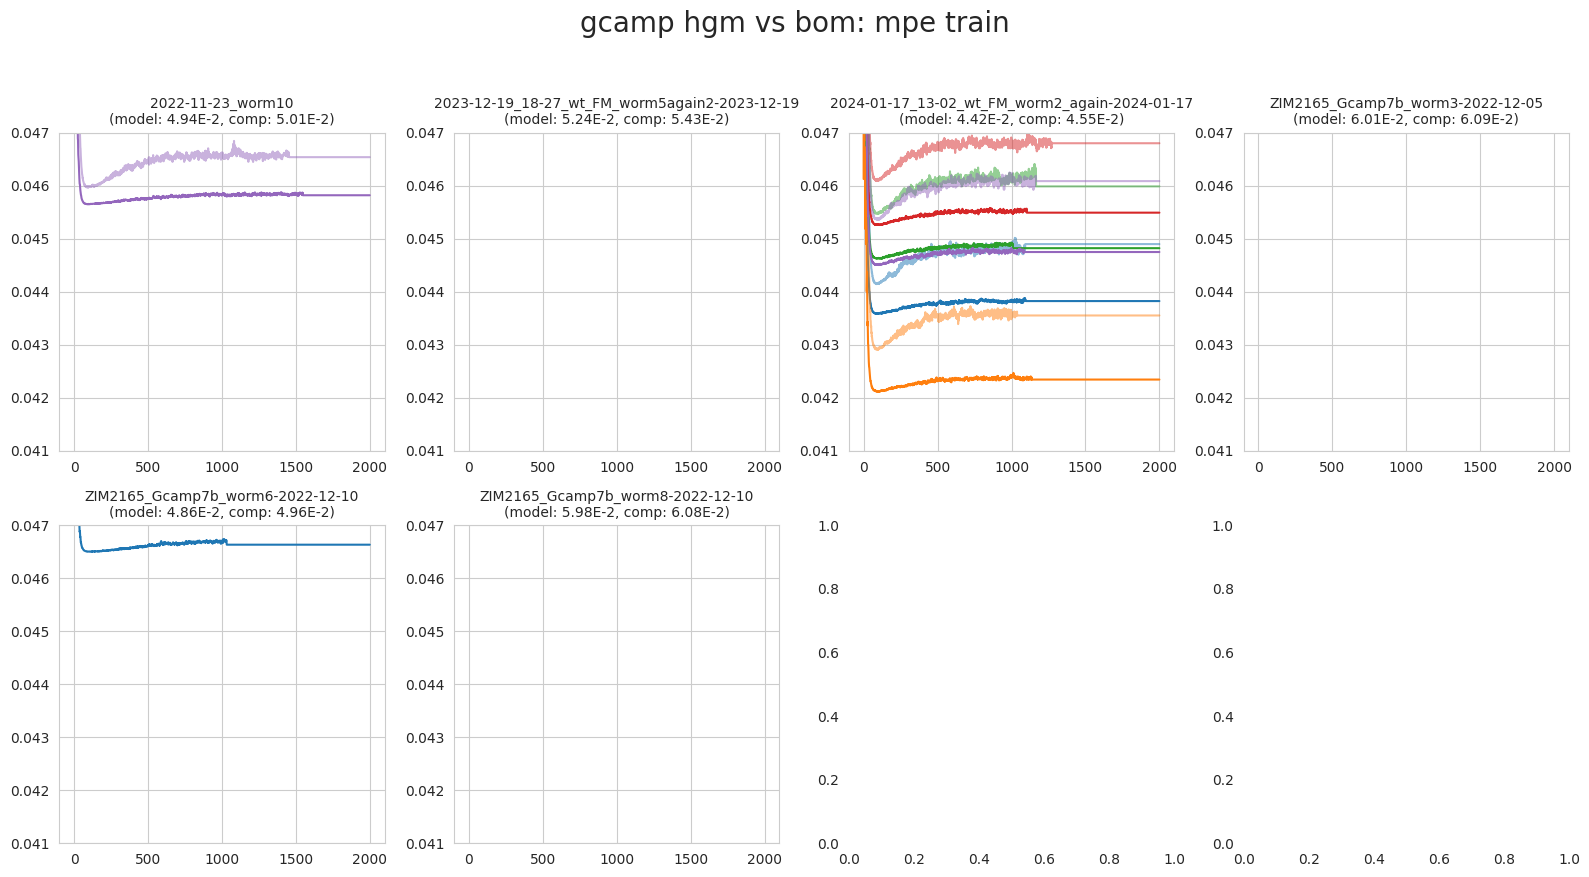

In [34]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames_gcamp,
							  hgm_models_mpe_losses_tr_gcamp, bom_models_mpe_losses_tr_gcamp,
							  plots_per_row=4, ylimits=(0.041, 0.047))

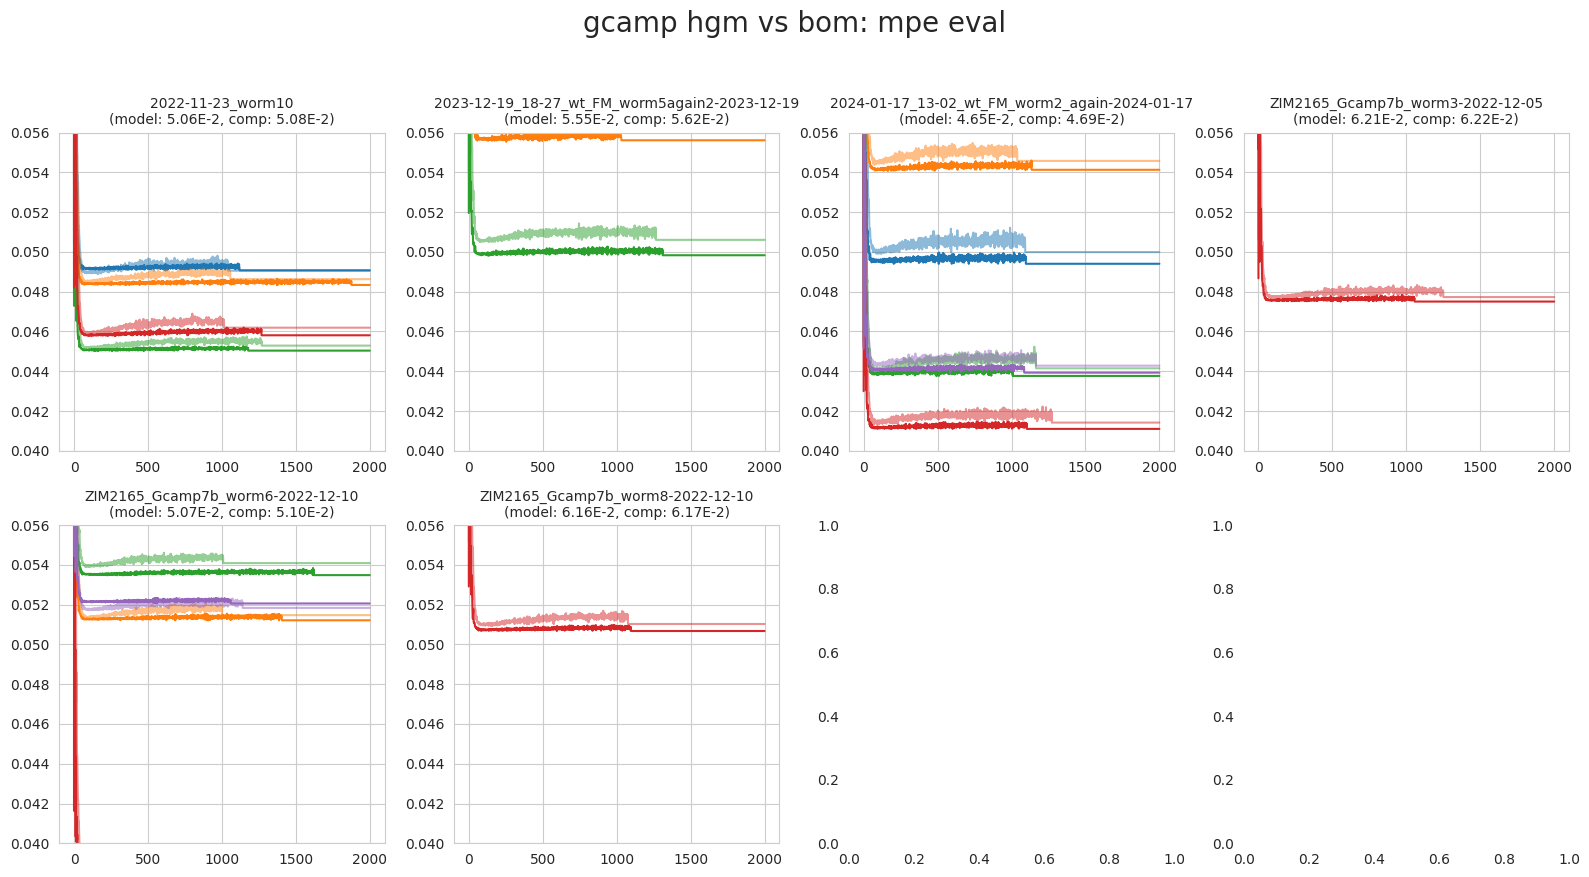

In [35]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe eval',
							  filenames_gcamp,
							  hgm_models_mpe_losses_gcamp, bom_models_mpe_losses_gcamp,
							  plots_per_row=4, ylimits=(0.04, 0.055))

### performance

In [36]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, bom_models_scores_gcamp, hgm_models_scores_gcamp)

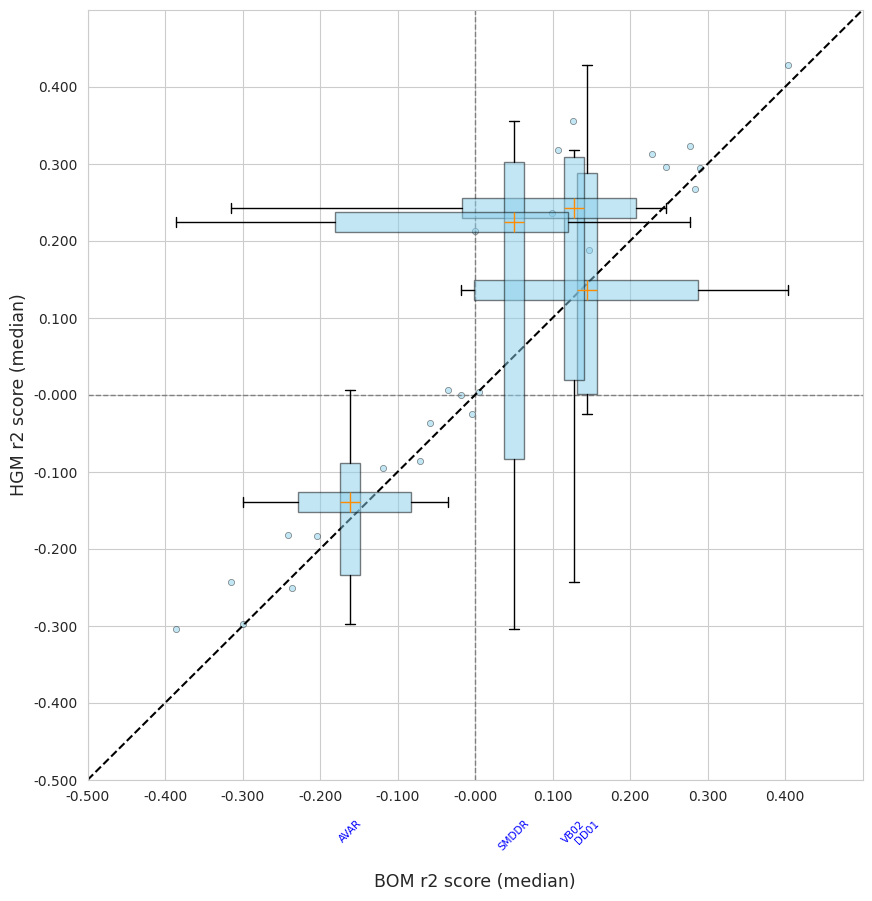

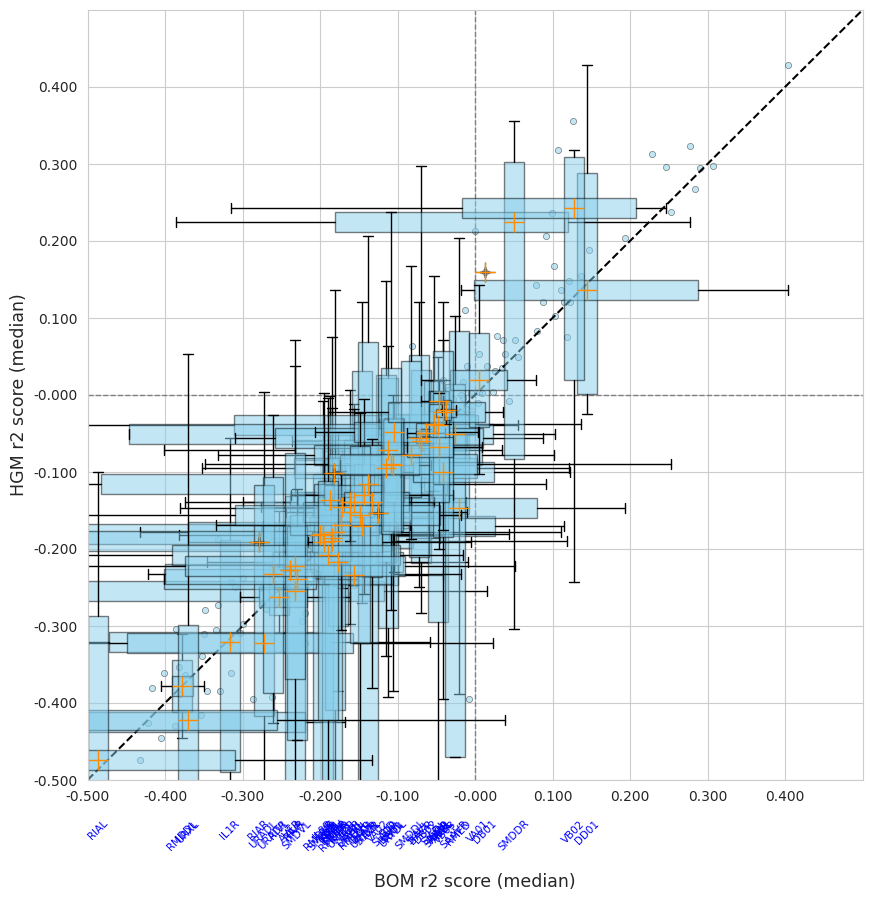

In [65]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
								 save_name=f'{'-'.join([str(_id) for _id in read_ids])}-sep-perf-w1-{w1:.0E}_w2-{w2:.0E}')

# plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
# 								 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
# 								 save_name=f'{'-'.join([str(_id) for _id in read_ids])}-sep-perf-w1-{w1:.0E}_w2-{w2:.0E}-allneurons')

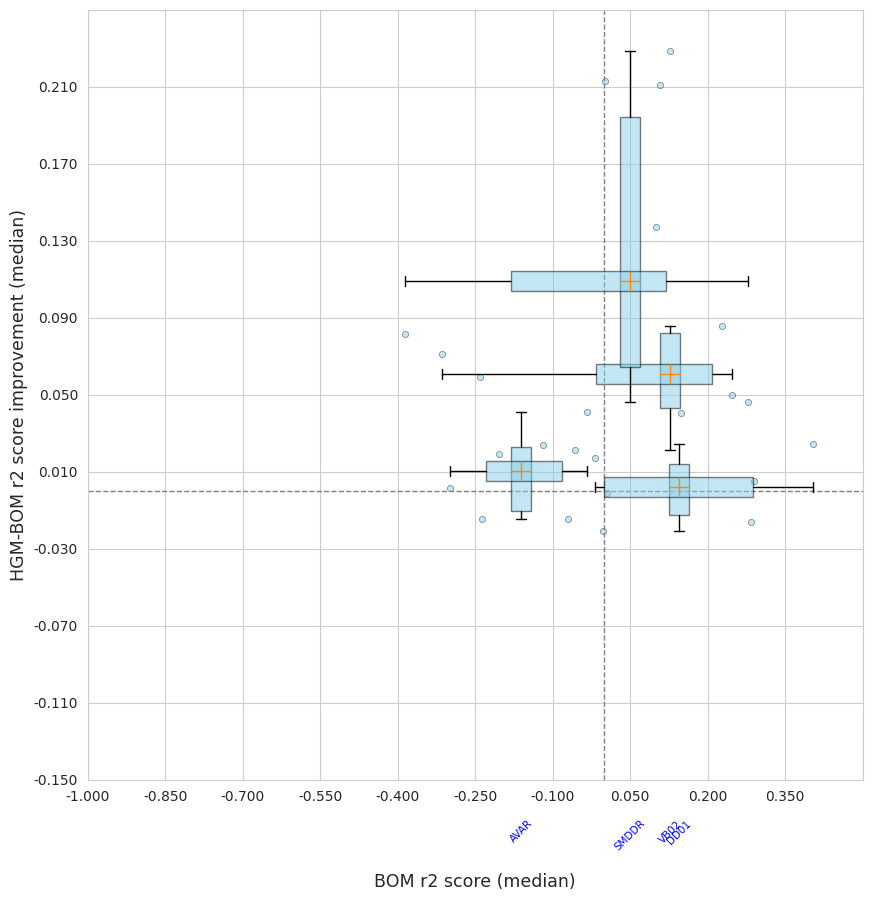

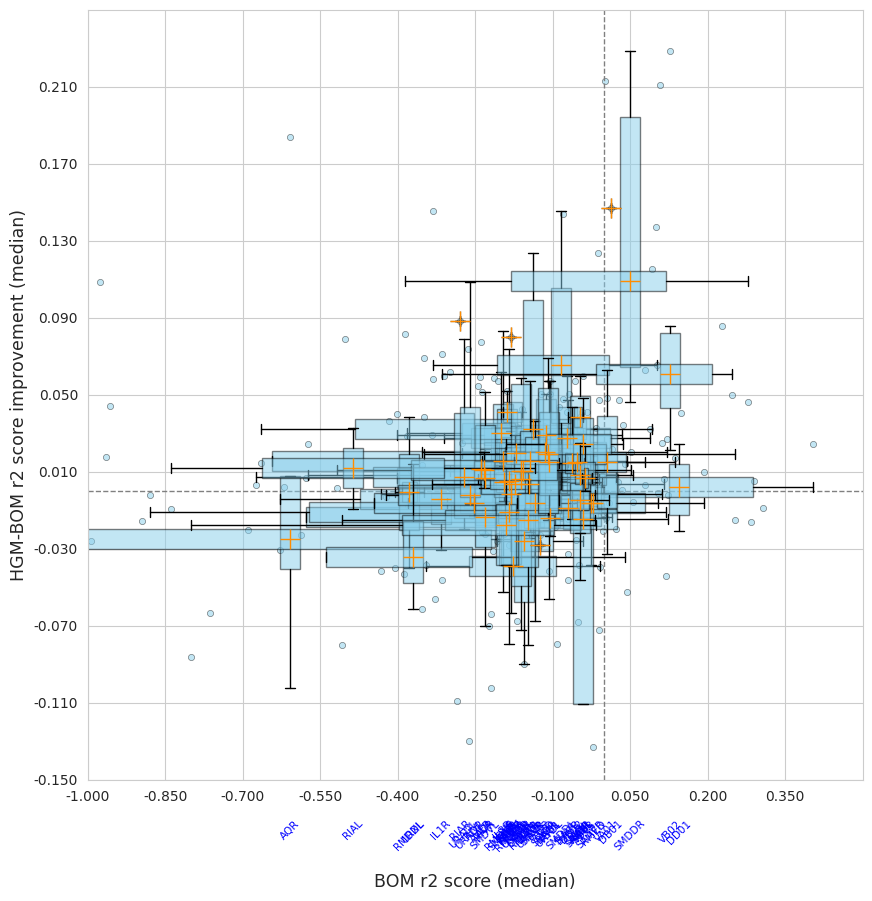

In [68]:
plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=(-1, 0.5, -0.15, 0.25), content_size=20,
								 save_name=f'{'-'.join([str(_id) for _id in read_ids])}-sep-impr-w1-{w1:.0E}_w2-{w2:.0E}')

# plot_utils.plot_improvement_plot(neuron_scores_gcamp, None,
# 								 limits=(-1, 0.5, -0.15, 0.25), content_size=20,
# 								 save_name=f'{'-'.join([str(_id) for _id in read_ids])}-sep-impr-w1-{w1:.0E}_w2-{w2:.0E}-allneurons')

### traces check

In [39]:
# blr_predicted_traces_gcamp = [[
# 	pd.DataFrame(data=model.predict(eigenworms_gcamp[i].values),
# 				 columns=traces_gcamp[i].columns) for model in blr_models_models_gcamp[i]
# ] for i in range(len(traces_art))]

bom_predicted_traces_gcamp = [[
	pd.DataFrame(data=bom.predict(eigenworms_gcamp[i].values, params['W']),
				 columns=traces_gcamp[i].columns) for params in bom_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

hgm_predicted_traces_gcamp = [[
	pd.DataFrame(data=hgm.predict(eigenworms_gcamp[i].values, neural_modes_gcamp[i].values, params['W1'], params['W2']),
				 columns=traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

In [40]:
# # best improvements
# neuron_diffs = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:10]
#
# # best hgm scores
# neuron_hgmss = {key: np.mean(neuron_scores_gcamp[key][1]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:10]

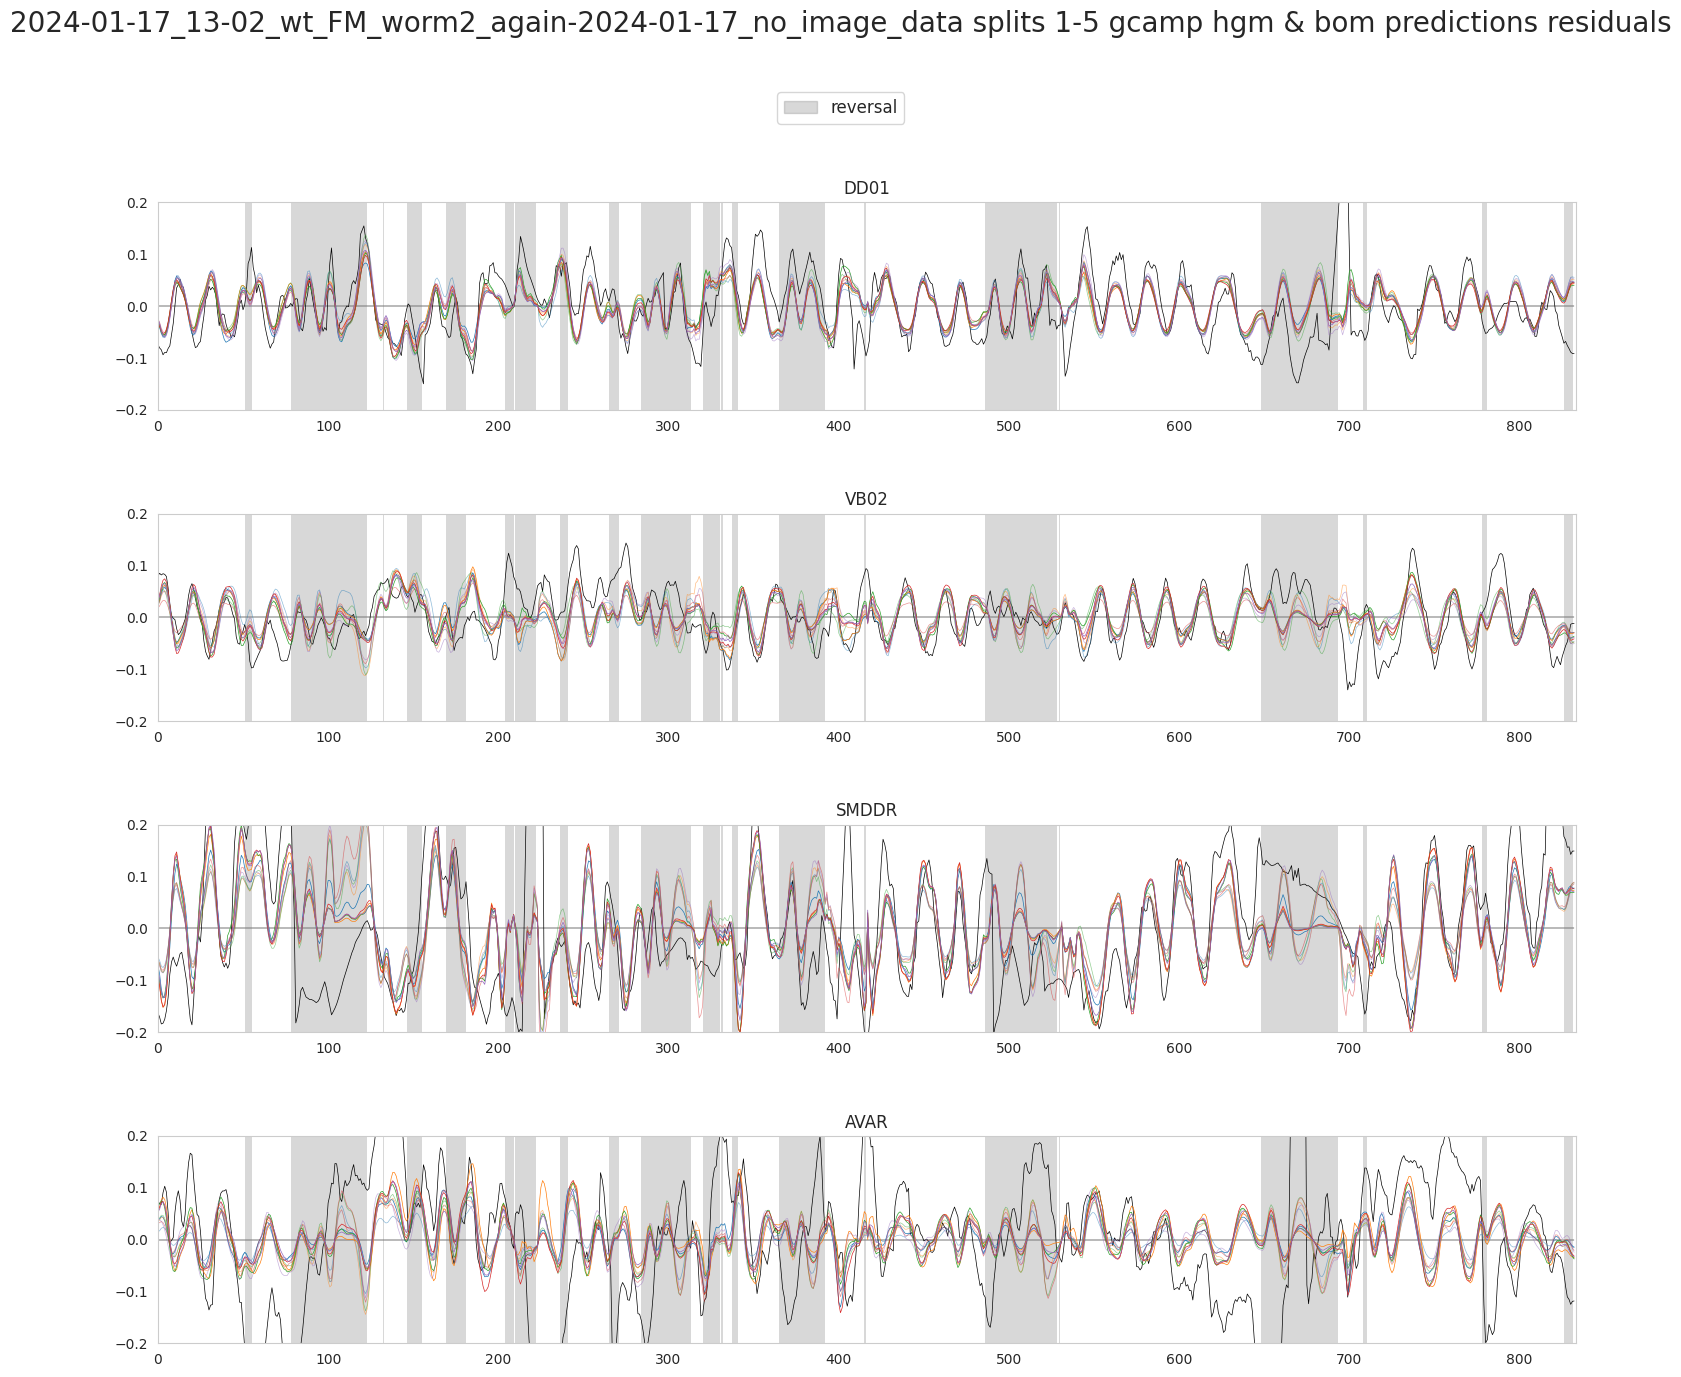

In [41]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} splits {1}-{splits} gcamp hgm & bom predictions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_residual_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
	[hgm_predicted_traces_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n] for i in range(splits)],
	[bom_predicted_traces_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n] for i in range(splits)],
	n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.2, 0.2),
	save_name=f'{plot_id}-sep-trac-w1-{w1:.0E}_w2-{w2:.0E}')

# GFP

### manifold

In [42]:
if gfp:
	(neural_modes_gfp, _,
	 traces_manifold_gfp, _,
	 cca_loadings_man_gfp,
	 vars_expl_man_gfp, vars_expl_man_rs_gfp) = train_utils.get_manifolds(traces_gfp,
													   discrete_states_gfp,
													   n_cc=dims, n_pc=5)

	traces_residual_gfp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gfp, traces_manifold_gfp)]

In [43]:
if gfp:
	plot_utils.plot_manifolds(filenames_gfp,
							  neural_modes_gfp,
							  discrete_states_gfp,
							  vars_expl_man_gfp, vars_expl_man_rs_gfp,
							  plots_per_row=4)

	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id)]}] gfp neural traces residual',
						   discrete_states_gfp[file_ids_gfp.index(plot_id)]['REV'],
						   traces_residual_gfp[file_ids_gfp.index(plot_id)][['VB02', 'AVAR']],
						   plots_per_row=1, ylimits=None)

### BLR

In [44]:
if gfp and regression:
	(blr_models_models_gfp,
	 blr_models_scores_gfp,
	 blr_models_losses_gfp, blr_models_losses_tr_gfp) = fit_models(filenames_gfp,
																			  discrete_states_gfp,
																			  eigenworms_gfp,
																			  traces_residual_gfp)

### BOM

In [45]:
if gfp:
	(bom_models_params_gfp,
	 bom_models_scores_gfp,
	 bom_models_losses_gfp, bom_models_losses_tr_gfp,
	 bom_models_mpe_losses_gfp, bom_models_mpe_losses_tr_gfp) = train_models(
		bom,
		filenames_gfp,
		discrete_states_gfp,
		eigenworms_gfp,
		traces_residual_gfp)

In [46]:
if gfp and regression:
	plot_utils.plot_losses_splits('gfp bom vs blr: mpe train',
								  filenames_gfp,
								  bom_models_mpe_losses_tr_gfp, [loss[:, None] * np.ones((1, bom_models_mpe_losses_tr_gfp[0].shape[1])) for loss in blr_models_losses_tr_gfp],
								  plots_per_row=4, ylimits=None)

In [47]:
if gfp and regression:
	plot_utils.plot_losses_splits('gfp bom vs blr: mpe eval',
								  filenames_gfp,
								  bom_models_mpe_losses_gfp, [loss[:, None] * np.ones((1, bom_models_mpe_losses_gfp[0].shape[1])) for loss in blr_models_losses_gfp],
								  plots_per_row=4, ylimits=None)

### HGM

In [48]:
if gfp:
	(hgm_models_params_gfp,
	 hgm_models_scores_gfp,
	 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
	 hgm_models_mpe_losses_gfp, hgm_models_mpe_losses_tr_gfp) = train_models(
		hgm,
		filenames_gfp,
		discrete_states_gfp,
		eigenworms_gfp,
		traces_residual_gfp,
		neural_modes_gfp)

In [49]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe train',
								  filenames_gfp,
								  hgm_models_mpe_losses_tr_gfp, bom_models_mpe_losses_tr_gfp,
								  plots_per_row=4, ylimits=None)

In [50]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe eval',
								  filenames_gfp,
								  hgm_models_mpe_losses_gfp, bom_models_mpe_losses_gfp,
								  plots_per_row=4, ylimits=None)

# assemble

In [51]:
if gfp:
	neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, bom_models_scores_gfp, hgm_models_scores_gfp)

# Plot

In [52]:
if gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in ['VB02', 'AVAR']}, neuron_scores_gfp,
									 limits=(-1, 0.5, -1, 0.6), content_size=20)

In [53]:
if gfp:
	plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in ['VB02', 'AVAR']}, neuron_scores_gfp,
									 limits=(-1, 0.5, -0.25, 0.5), content_size=20)